In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import umap
from pathlib import Path
from sklearn.decomposition import PCA

BASE_DIR = Path(r"C:\Projects\cancer-classifier")
PROC_DIR = BASE_DIR / "data" / "processed"
FIG_DIR  = BASE_DIR / "outputs" / "figures"

# Load processed data
df    = pd.read_parquet(PROC_DIR / "dataset_scaled.parquet")
genes = pd.read_csv(PROC_DIR / "selected_genes.csv").iloc[:, 0].tolist()

# Fix any stale GBM labels
df["cancer_type"] = df["cancer_type"].replace("GBM", "LGG")

X = df[genes].values
y = df["cancer_type"].values

# Build palette AFTER confirming actual labels in data
LABELS  = sorted(df["cancer_type"].unique().tolist())
PALETTE = dict(zip(LABELS, sns.color_palette("Set2", len(LABELS))))
colors  = [PALETTE[l] for l in y]

print(f"Dataset: {X.shape[0]} samples × {X.shape[1]} genes")
print(f"Classes: {pd.Series(y).value_counts().to_dict()}")
print(f"Palette: {list(PALETTE.keys())}")

Dataset: 792 samples × 340 genes
Classes: {'LGG': 200, 'BRCA': 199, 'KIRC': 198, 'LUAD': 133, 'COAD': 62}
Palette: ['BRCA', 'COAD', 'KIRC', 'LGG', 'LUAD']


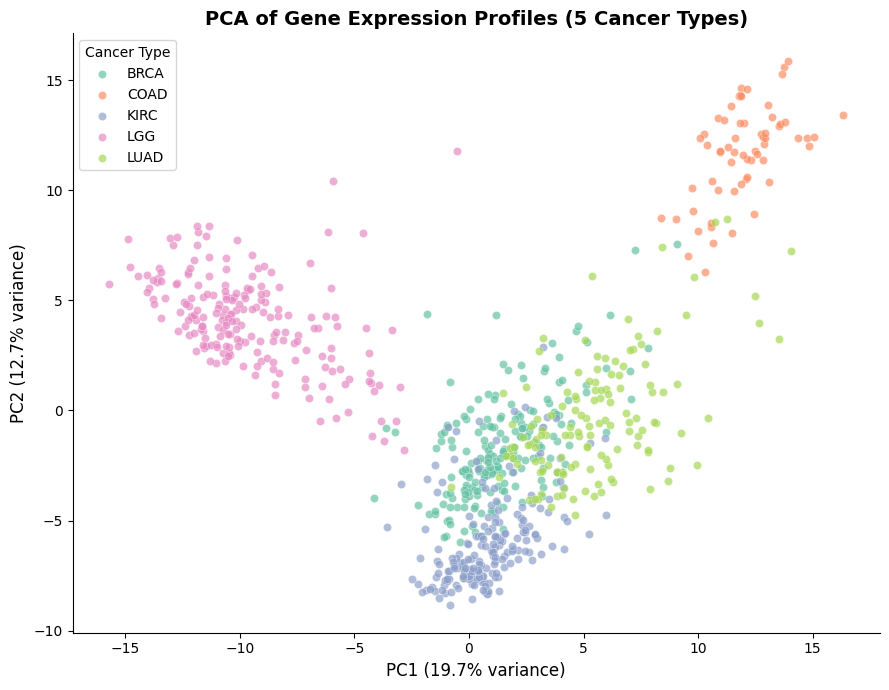

✅ PCA plot saved!


In [12]:
# PCA first: fast, interpretable, good baseline
pca       = PCA(n_components=2, random_state=42)
X_pca     = pca.fit_transform(X)
var_exp   = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(9, 7))
for label in LABELS:
    mask = y == label
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=[PALETTE[label]], label=label,
               alpha=0.7, s=35, edgecolors="white", linewidths=0.3)

ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% variance)", fontsize=12)
ax.set_title("PCA of Gene Expression Profiles (5 Cancer Types)", fontsize=14, fontweight="bold")
ax.legend(title="Cancer Type", fontsize=10)
ax.spines[["top","right"]].set_visible(False)

plt.tight_layout()
plt.savefig(FIG_DIR / "02_pca.png", dpi=150)
plt.show()
print("✅ PCA plot saved!")

In [7]:
# Check what labels actually exist in the saved file
print("Labels in parquet file:", df["cancer_type"].unique())

# Rename GBM → LGG if it's still in there
if "GBM" in df["cancer_type"].values:
    print("⚠️ Found GBM labels — renaming to LGG...")
    df["cancer_type"] = df["cancer_type"].replace("GBM", "LGG")
    y = df["cancer_type"].values
    print("✅ Fixed! Labels now:", df["cancer_type"].unique())

Labels in parquet file: <ArrowStringArray>
['BRCA', 'LUAD', 'KIRC', 'LGG', 'COAD']
Length: 5, dtype: str


In [10]:
# Check exact label values including hidden characters
for val in df["cancer_type"].unique():
    print(repr(val))  # repr shows hidden spaces/chars

'BRCA'
'LUAD'
'KIRC'
'LGG'
'COAD'


Running UMAP (this takes ~1–2 min)...


C:\Users\King\miniconda3\envs\cancer_clf\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP done!


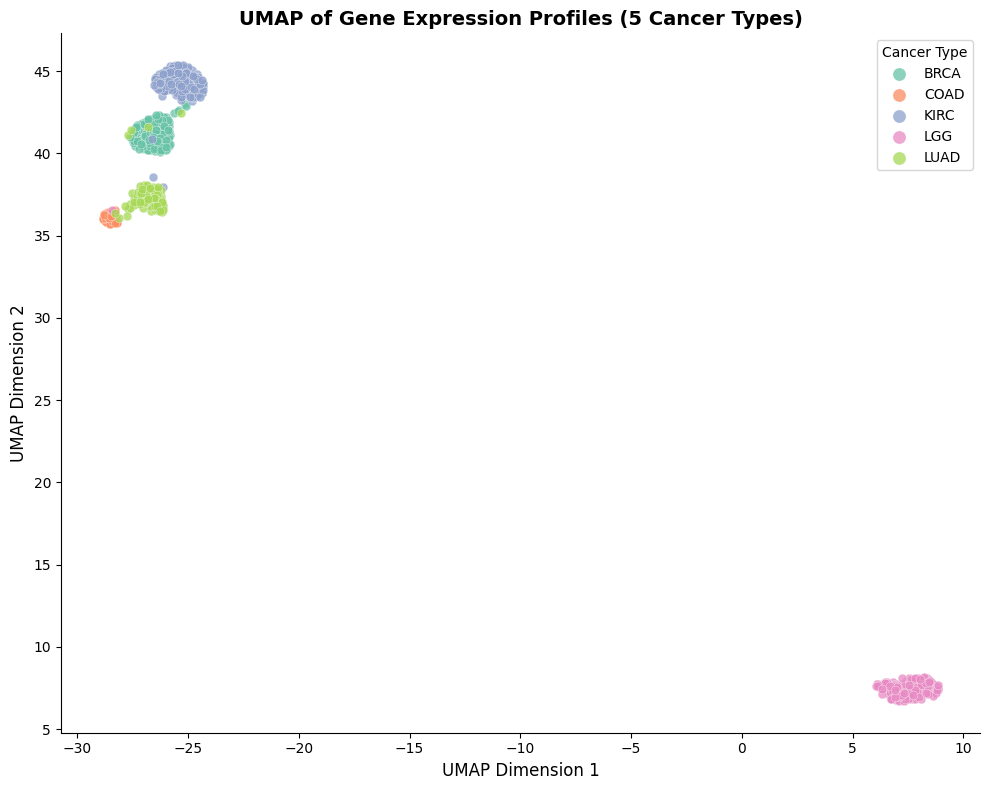

✅ UMAP plot saved!


In [13]:
# UMAP captures non-linear structure PCA misses
# n_neighbors: local vs global structure tradeoff
# min_dist: how tightly points cluster
print("Running UMAP (this takes ~1–2 min)...")
reducer  = umap.UMAP(n_neighbors=30, min_dist=0.1,
                     n_components=2, random_state=42,
                     metric="euclidean")
X_umap   = reducer.fit_transform(X)
print("UMAP done!")

fig, ax = plt.subplots(figsize=(10, 8))
for label in LABELS:
    mask = y == label
    ax.scatter(X_umap[mask, 0], X_umap[mask, 1],
               c=[PALETTE[label]], label=label,
               alpha=0.75, s=40, edgecolors="white", linewidths=0.3)

ax.set_xlabel("UMAP Dimension 1", fontsize=12)
ax.set_ylabel("UMAP Dimension 2", fontsize=12)
ax.set_title("UMAP of Gene Expression Profiles (5 Cancer Types)", fontsize=14, fontweight="bold")
ax.legend(title="Cancer Type", fontsize=10, markerscale=1.5)
ax.spines[["top","right"]].set_visible(False)

plt.tight_layout()
plt.savefig(FIG_DIR / "03_umap.png", dpi=150)
plt.show()
print("✅ UMAP plot saved!")

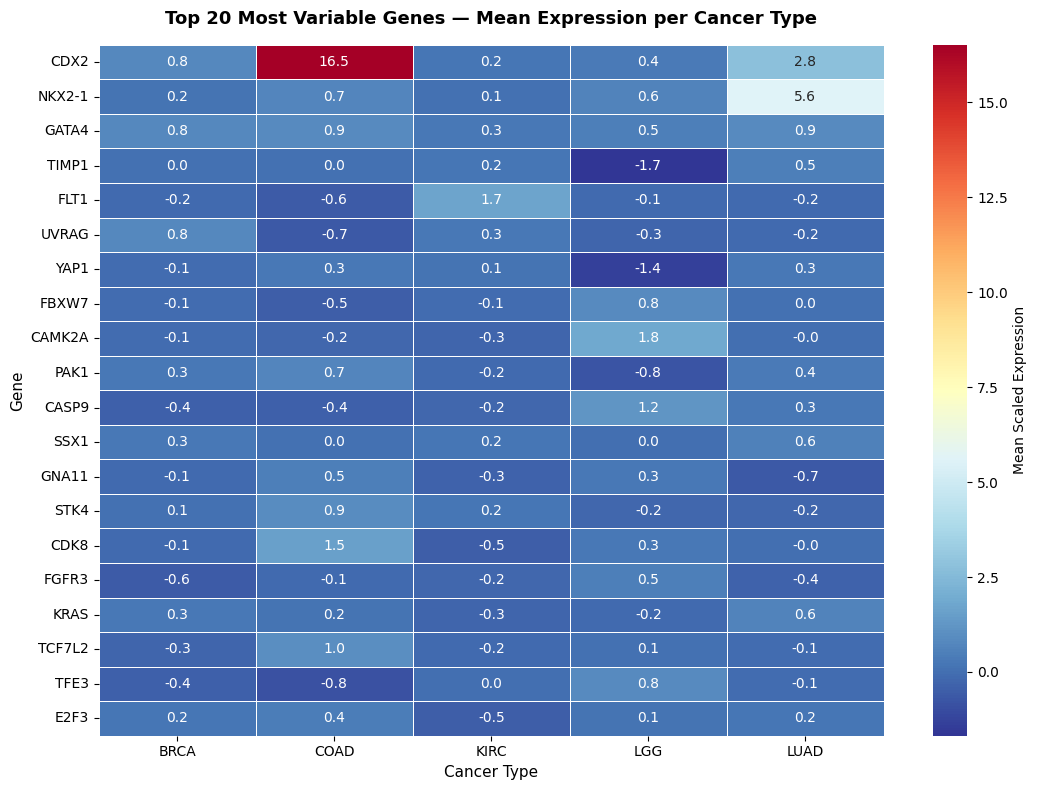

✅ Heatmap saved!


In [14]:
# Show which genes vary most dramatically across cancer types
top_genes = pd.Series(
    df[genes].var().values, index=genes
).nlargest(20).index.tolist()

# Mean expression per cancer type for top genes
heatmap_data = df.groupby("cancer_type")[top_genes].mean().T

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(heatmap_data,
            cmap="RdYlBu_r",
            annot=True, fmt=".1f",
            linewidths=0.5,
            ax=ax,
            cbar_kws={"label": "Mean Scaled Expression"})

ax.set_title("Top 20 Most Variable Genes — Mean Expression per Cancer Type",
             fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Cancer Type", fontsize=11)
ax.set_ylabel("Gene", fontsize=11)
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.savefig(FIG_DIR / "04_top_genes_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Heatmap saved!")

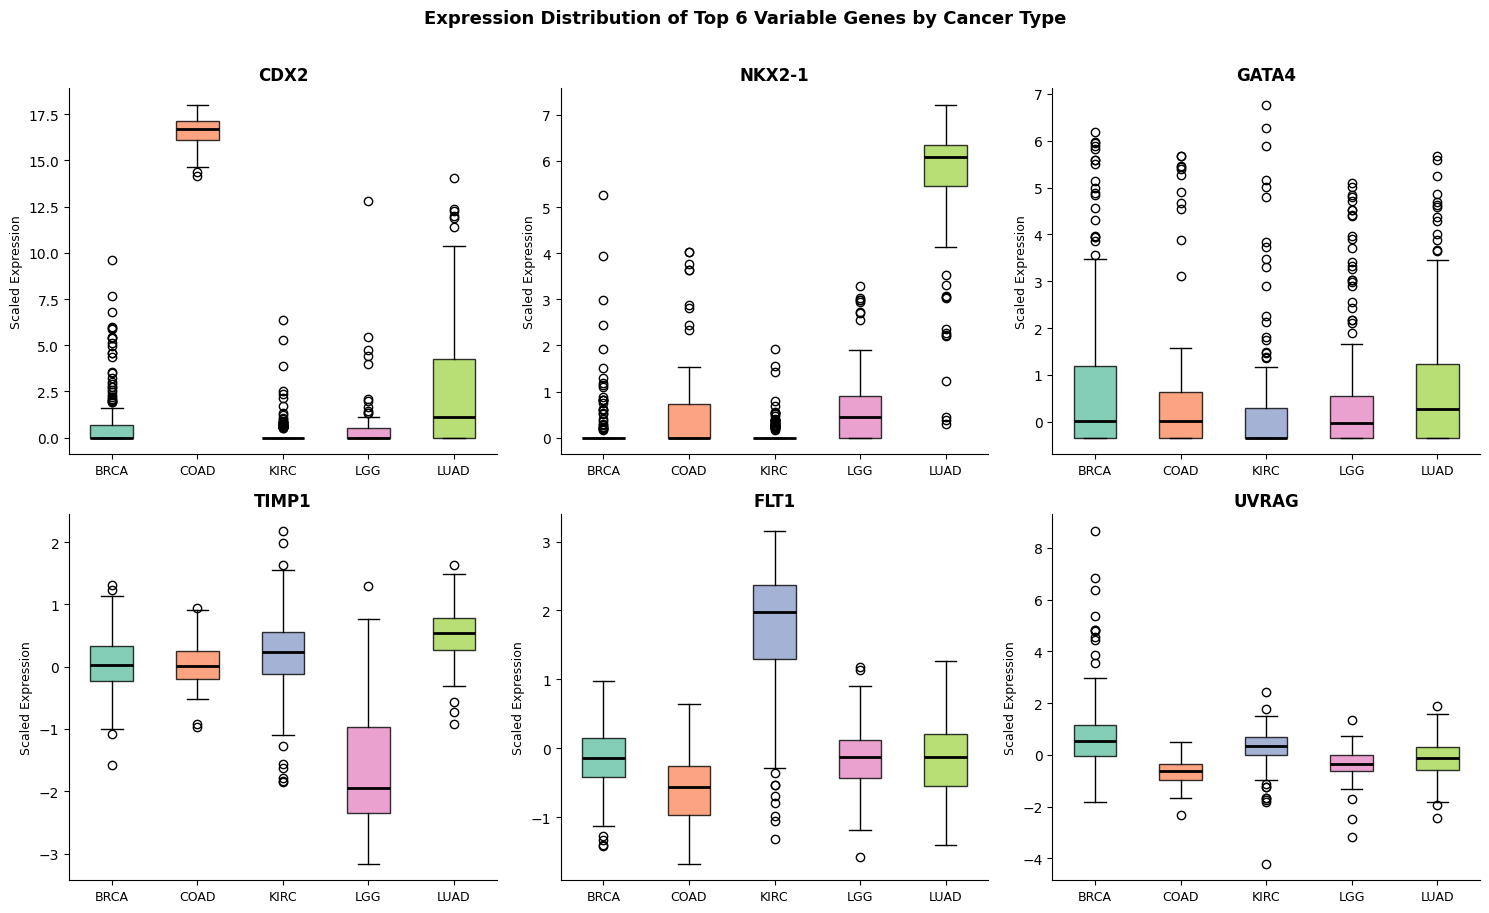

✅ Boxplot saved!


In [15]:
top6 = top_genes[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, gene in enumerate(top6):
    data_per_class = [df.loc[df["cancer_type"] == l, gene].values for l in LABELS]
    bp = axes[i].boxplot(data_per_class, patch_artist=True, notch=False,
                         medianprops=dict(color="black", linewidth=2))
    for patch, label in zip(bp["boxes"], LABELS):
        patch.set_facecolor(PALETTE[label])
        patch.set_alpha(0.8)
    axes[i].set_title(f"{gene}", fontsize=12, fontweight="bold")
    axes[i].set_xticks(range(1, len(LABELS)+1))
    axes[i].set_xticklabels(LABELS, fontsize=9)
    axes[i].set_ylabel("Scaled Expression", fontsize=9)
    axes[i].spines[["top","right"]].set_visible(False)

plt.suptitle("Expression Distribution of Top 6 Variable Genes by Cancer Type",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_top_genes_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Boxplot saved!")

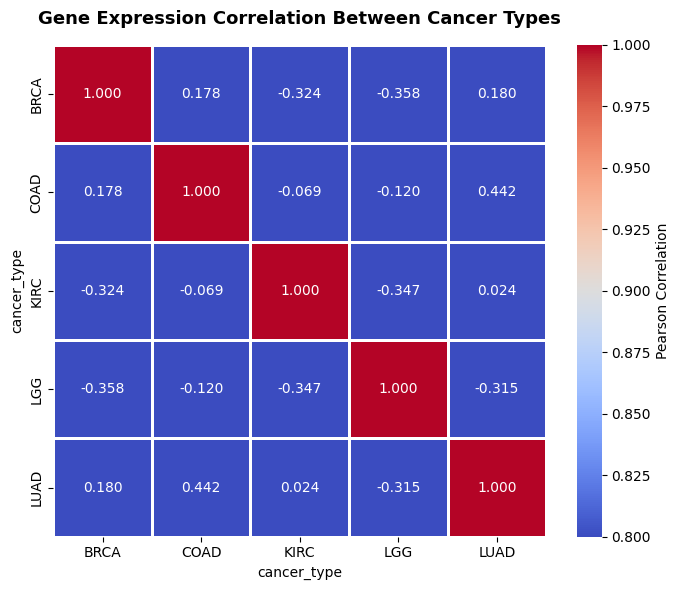

✅ Correlation heatmap saved!


In [16]:
# How similar/different are the cancer types overall?
mean_profiles = df.groupby("cancer_type")[genes].mean()
corr_matrix   = mean_profiles.T.corr()

fig, ax = plt.subplots(figsize=(7, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix,
            annot=True, fmt=".3f",
            cmap="coolwarm", vmin=0.8, vmax=1.0,
            linewidths=1, ax=ax,
            cbar_kws={"label": "Pearson Correlation"})

ax.set_title("Gene Expression Correlation Between Cancer Types",
             fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_cancer_correlation.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Correlation heatmap saved!")